# Training deteksi Musuh dan Bukan Musuh dengan YOLO26

Notebook ini mengunduh Roboflow dataset versi 1, memeriksa kelas dan anotasinya, lalu melatih serta mengevaluasi model object detection. Ubah MODEL_SIZE dari n ke s, m, l, atau x untuk berpindah varian.

Untuk membuat venv dan memasang dependensi, jalankan setup_training_env.ps1 dari PowerShell 7. API key diminta saat runtime atau dibaca dari ROBOFLOW_API_KEY. Notebook tidak menyimpan key di source maupun output.

## Hasil audit awal dataset v1

Roboflow menamai ID 0 sebagai ally dan ID 1 sebagai enemy. Training YAML menampilkan keduanya sebagai Bukan Musuh (ally) dan Musuh (enemy), dengan urutan ID tetap sama.

| Split | Gambar | Label kosong | Box Bukan Musuh | Box Musuh |
| --- | ---: | ---: | ---: | ---: |
| Train | 935 | 148 | 2.316 | 2.280 |
| Validation | 267 | 43 | 708 | 615 |
| Test | 134 | 27 | 340 | 270 |
| Total | 1.336 | 218 | 3.364 | 3.165 |

Tidak ditemukan file label yang hilang, baris anotasi rusak, ID kelas di luar batas, atau bounding box di luar rentang YOLO. README ekspor menyatakan semua gambar sudah di-resize ke 640x640 dengan metode stretch; resolusi training awal disamakan pada 640. Lisensi dataset tercatat CC BY 4.0.


## 1. Konfigurasi proyek

Jalankan notebook dari folder root repository dan pilih kernel UAV YOLO26 Training GPU. Mulai dengan varian n; batch memakai mode auto Ultralytics agar menyesuaikan memori GPU yang tersedia.


In [1]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = Path.cwd().resolve()
DATASET_DIR = PROJECT_ROOT / "datasets" / "enemy-detection-1-fps-v1"
DATASET_YAML = DATASET_DIR / "data.yaml"
LOCAL_DATA_YAML = DATASET_DIR / "data_yolo26_local.yaml"

ROBOFLOW_WORKSPACE = "aaaa-g4pgj"
ROBOFLOW_PROJECT = "enemy-detection-1-fps"
ROBOFLOW_VERSION = 1
ROBOFLOW_FORMAT = "yolo26"

# Pilih salah satu: n, s, m, l, x
MODEL_SIZE = "n"
MODEL_SIZES = {"n", "s", "m", "l", "x"}
if MODEL_SIZE not in MODEL_SIZES:
    raise ValueError(f"MODEL_SIZE harus salah satu dari {sorted(MODEL_SIZES)}")
MODEL_WEIGHTS = f"yolo26{MODEL_SIZE}.pt"

print(f"Project: {PROJECT_ROOT}")
print(f"Dataset: {DATASET_DIR}")
print(f"Model: {MODEL_WEIGHTS}")
print(f"Python: {sys.executable}")


Project: F:\Telkom  x Machung\uav_enemy_detection_pt1
Dataset: F:\Telkom  x Machung\uav_enemy_detection_pt1\datasets\enemy-detection-1-fps-v1
Model: yolo26n.pt
Python: f:\Telkom  x Machung\uav_enemy_detection_pt1\.venv-training\Scripts\python.exe


## 2. Cek runtime dan GPU

Cell ini memastikan notebook memakai .venv-training serta menampilkan GPU dan VRAM yang tersedia. Penggunaan GPU akan dipilih otomatis jika CUDA aktif.


In [2]:
import torch
import ultralytics

expected_venv = (PROJECT_ROOT / ".venv-training").resolve()
actual_python = Path(sys.executable).resolve()
if expected_venv not in actual_python.parents:
    raise RuntimeError(
        f"Kernel bukan dari venv proyek. Interpreter aktif: {actual_python}. "
        "Pilih kernel UAV YOLO26 Training GPU."
    )

DEVICE = 0 if torch.cuda.is_available() else "cpu"
USE_AMP = torch.cuda.is_available()

print(f"Ultralytics: {ultralytics.__version__}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA aktif: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    free_bytes, total_bytes = torch.cuda.mem_get_info(0)
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM tersedia: {free_bytes / 1024**3:.2f} / {total_bytes / 1024**3:.2f} GiB")
print(f"Device training: {DEVICE}")


Ultralytics: 8.4.165
PyTorch: 2.12.1+cu130
CUDA aktif: True
GPU: NVIDIA GeForce RTX 5070
VRAM tersedia: 10.78 / 11.94 GiB
Device training: 0


## 3. Unduh dataset Roboflow

Masukkan key melalui prompt tersembunyi, atau set ROBOFLOW_API_KEY sebelum membuka Jupyter. Dataset lokal yang sudah ada akan dipakai ulang.


In [3]:
from getpass import getpass
from roboflow import Roboflow

if DATASET_YAML.exists():
    print(f"Dataset lokal sudah tersedia: {DATASET_DIR}")
else:
    api_key = "2oeGI3QWbiYo6HNrErIp"
    if not api_key.strip():
        raise ValueError("Roboflow API key kosong.")

    rf = Roboflow(api_key=api_key.strip())
    project = rf.workspace(ROBOFLOW_WORKSPACE).project(ROBOFLOW_PROJECT)
    version = project.version(ROBOFLOW_VERSION)
    dataset = version.download(ROBOFLOW_FORMAT, location=str(DATASET_DIR))
    DATASET_DIR = Path(dataset.location).resolve()
    DATASET_YAML = DATASET_DIR / "data.yaml"
    LOCAL_DATA_YAML = DATASET_DIR / "data_yolo26_local.yaml"
    del api_key, rf

if not DATASET_YAML.exists():
    raise FileNotFoundError(f"data.yaml tidak ditemukan: {DATASET_YAML}")
print(f"Dataset siap: {DATASET_DIR}")
print(f"Konfigurasi Roboflow: {DATASET_YAML}")


Dataset lokal sudah tersedia: F:\Telkom  x Machung\uav_enemy_detection_pt1\datasets\enemy-detection-1-fps-v1
Dataset siap: F:\Telkom  x Machung\uav_enemy_detection_pt1\datasets\enemy-detection-1-fps-v1
Konfigurasi Roboflow: F:\Telkom  x Machung\uav_enemy_detection_pt1\datasets\enemy-detection-1-fps-v1\data.yaml


## 4. Baca konfigurasi dan periksa dua kelas

Dataset versi ini memakai ID 0 = ally dan ID 1 = enemy. Notebook menampilkan nama yang sesuai target sebagai Bukan Musuh (ally) dan Musuh (enemy) tanpa mengubah urutan ID. Pastikan pemetaan tersebut cocok dengan makna anotasi sebelum training.

Untuk object detection, kelas Bukan Musuh harus memiliki bounding box pada objek yang dimaksud; gambar latar tanpa objek cukup menjadi contoh negatif dengan file label kosong.


In [4]:
import yaml

with DATASET_YAML.open("r", encoding="utf-8") as file:
    dataset_meta = yaml.safe_load(file)

raw_names = dataset_meta.get("names")
if isinstance(raw_names, dict):
    source_class_names = [str(raw_names[key]) for key in sorted(raw_names, key=lambda value: int(value))]
elif isinstance(raw_names, list):
    source_class_names = [str(name) for name in raw_names]
else:
    raise ValueError("data.yaml harus berisi 'names' sebagai list atau mapping.")

declared_nc = int(dataset_meta.get("nc", len(source_class_names)))
if declared_nc != len(source_class_names):
    raise ValueError(f"nc={declared_nc}, tetapi jumlah names={len(source_class_names)}")
if len(source_class_names) != 2:
    raise ValueError(f"Dataset harus memiliki 2 kelas; ditemukan {len(source_class_names)}: {source_class_names}")

class_aliases = {"ally": "Bukan Musuh (ally)", "enemy": "Musuh (enemy)"}
normalized_source_names = [name.strip().lower() for name in source_class_names]
if set(normalized_source_names) == set(class_aliases):
    class_names = [class_aliases[name] for name in normalized_source_names]
else:
    class_names = source_class_names

print("Mapping class ID (nama sumber -> nama yang dipakai training):")
for class_id, (source_name, class_name) in enumerate(zip(source_class_names, class_names)):
    print(f"  {class_id}: {source_name} -> {class_name}")
print()
print("Cocokkan mapping ini dengan target Musuh dan Bukan Musuh sebelum melanjutkan.")


Mapping class ID (nama sumber -> nama yang dipakai training):
  0: ally -> Bukan Musuh (ally)
  1: enemy -> Musuh (enemy)

Cocokkan mapping ini dengan target Musuh dan Bukan Musuh sebelum melanjutkan.


## 5. Audit jumlah gambar dan anotasi

Audit menghitung gambar, file label, jumlah bounding box per kelas, label kosong, dan koordinat yang tidak valid pada train/val/test. Export Roboflow versi ini berisi gambar 640x640 hasil resize stretch.


In [5]:
from collections import Counter
import pandas as pd

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

def resolve_split_path(split_name):
    configured_path = dataset_meta.get(split_name)
    if not configured_path:
        return None
    candidate = Path(str(configured_path))
    if candidate.is_absolute():
        resolved = candidate.resolve()
    else:
        configured_root = Path(str(dataset_meta.get("path", DATASET_DIR)))
        if not configured_root.is_absolute():
            configured_root = (DATASET_DIR / configured_root).resolve()
        resolved = (configured_root / candidate).resolve()
        if not resolved.exists():
            portable_parts = [part for part in candidate.parts if part not in (".", "..")]
            resolved = DATASET_DIR.joinpath(*portable_parts).resolve()
        if not resolved.exists():
            resolved = (DATASET_DIR / candidate).resolve()
    return resolved

SPLIT_PATHS = {}
for split_name in ("train", "val", "test"):
    split_path = resolve_split_path(split_name)
    if split_path is not None:
        if not split_path.is_dir():
            raise FileNotFoundError(f"Folder {split_name} tidak ditemukan: {split_path}")
        SPLIT_PATHS[split_name] = split_path

if "train" not in SPLIT_PATHS or "val" not in SPLIT_PATHS:
    raise ValueError("Dataset wajib memiliki split train dan val.")

def image_files(folder):
    return sorted(path for path in folder.rglob("*") if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS)

def label_path_for(image_path, images_dir):
    relative_image = image_path.relative_to(images_dir)
    return images_dir.parent / "labels" / relative_image.with_suffix(".txt")

audit_rows = []
CLASS_BOX_COUNTS = {split: Counter() for split in SPLIT_PATHS}
SAMPLE_IMAGES = {split: image_files(folder) for split, folder in SPLIT_PATHS.items()}

for split_name, images_dir in SPLIT_PATHS.items():
    images = SAMPLE_IMAGES[split_name]
    missing_labels = 0
    empty_labels = 0
    malformed_lines = 0
    invalid_class_ids = 0
    invalid_boxes = 0
    total_boxes = 0

    for image_path in images:
        label_path = label_path_for(image_path, images_dir)
        if not label_path.exists():
            missing_labels += 1
            continue
        lines = [line.strip() for line in label_path.read_text(encoding="utf-8").splitlines() if line.strip()]
        if not lines:
            empty_labels += 1
            continue
        for line in lines:
            parts = line.split()
            if len(parts) != 5:
                malformed_lines += 1
                continue
            try:
                class_id = int(float(parts[0]))
                x_center, y_center, box_width, box_height = map(float, parts[1:])
            except ValueError:
                malformed_lines += 1
                continue
            if not 0 <= class_id < len(class_names):
                invalid_class_ids += 1
                continue
            if not (0 <= x_center <= 1 and 0 <= y_center <= 1 and 0 < box_width <= 1 and 0 < box_height <= 1):
                invalid_boxes += 1
            CLASS_BOX_COUNTS[split_name][class_id] += 1
            total_boxes += 1

    row = {
        "split": split_name,
        "images": len(images),
        "missing_label_files": missing_labels,
        "empty_label_files": empty_labels,
        "boxes_total": total_boxes,
        "malformed_lines": malformed_lines,
        "invalid_class_ids": invalid_class_ids,
        "invalid_boxes": invalid_boxes,
    }
    for class_id, class_name in enumerate(class_names):
        row[f"boxes: {class_name}"] = CLASS_BOX_COUNTS[split_name][class_id]
    audit_rows.append(row)

audit_df = pd.DataFrame(audit_rows).set_index("split")
display(audit_df)


,images,missing_label_files,empty_label_files,boxes_total,malformed_lines,invalid_class_ids,invalid_boxes,boxes: Bukan Musuh (ally),boxes: Musuh (enemy)
split,,,,,,,,,
train,935,0,148,4596,0,0,0,2316,2280
val,267,0,43,1323,0,0,0,708,615
test,134,0,27,610,0,0,0,340,270


Split,train,val,test
Kelas,,,
Bukan Musuh (ally),2316,708,340
Musuh (enemy),2280,615,270


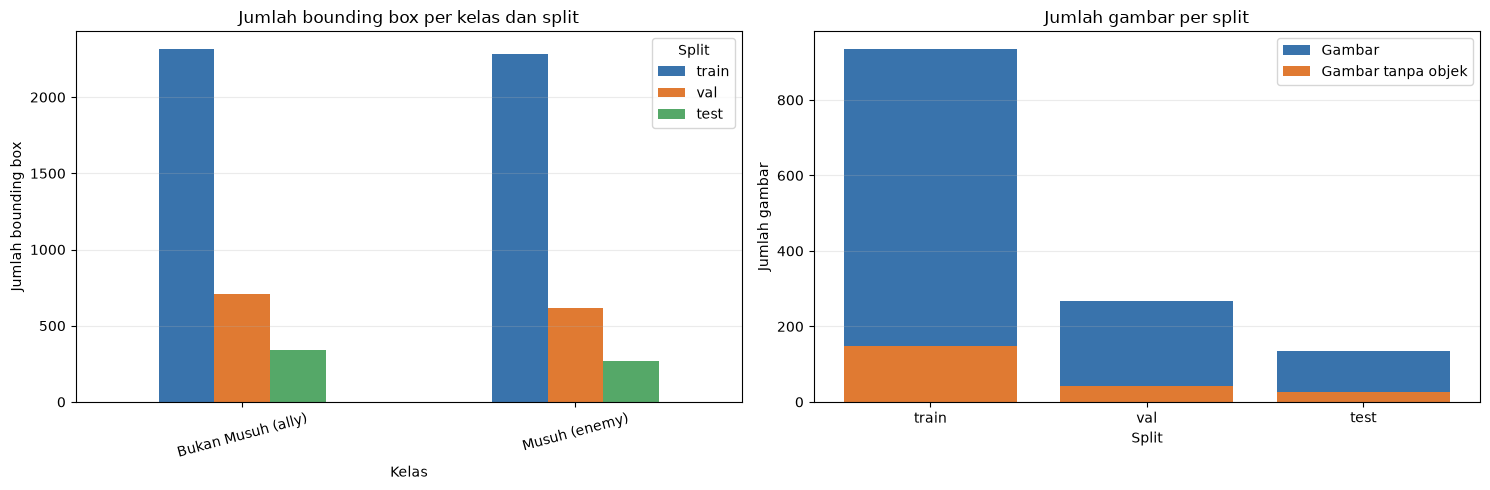

Grafik distribusi dataset tersimpan: F:\Telkom  x Machung\uav_enemy_detection_pt1\runs\dataset\class_distribution.png


In [6]:
import matplotlib.pyplot as plt
from IPython.display import display

DATASET_PLOT_DIR = PROJECT_ROOT / "runs" / "dataset"
DATASET_PLOT_DIR.mkdir(parents=True, exist_ok=True)

split_names = list(SPLIT_PATHS)
class_counts = pd.DataFrame(
    {split_name: [CLASS_BOX_COUNTS[split_name][class_id] for class_id in range(len(class_names))]
     for split_name in split_names},
    index=class_names,
)
image_counts = [len(SAMPLE_IMAGES[split_name]) for split_name in split_names]
empty_label_counts = [int(audit_df.loc[split_name, "empty_label_files"]) for split_name in split_names]

display(class_counts.rename_axis("Kelas").rename_axis("Split", axis="columns"))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
class_counts.plot(kind="bar", ax=axes[0], color=["#3973ac", "#e07a32", "#55a868"][:len(split_names)])
axes[0].set_title("Jumlah bounding box per kelas dan split")
axes[0].set_xlabel("Kelas")
axes[0].set_ylabel("Jumlah bounding box")
axes[0].tick_params(axis="x", rotation=15)
axes[0].legend(title="Split")

positions = range(len(split_names))
axes[1].bar(positions, image_counts, color="#3973ac", label="Gambar")
axes[1].bar(positions, empty_label_counts, color="#e07a32", label="Gambar tanpa objek")
axes[1].set_xticks(list(positions), split_names)
axes[1].set_title("Jumlah gambar per split")
axes[1].set_xlabel("Split")
axes[1].set_ylabel("Jumlah gambar")
axes[1].legend()
for axis in axes:
    axis.grid(axis="y", alpha=0.25)
fig.tight_layout()
DATASET_DISTRIBUTION_PLOT = DATASET_PLOT_DIR / "class_distribution.png"
fig.savefig(DATASET_DISTRIBUTION_PLOT, dpi=160, bbox_inches="tight")
plt.show()
print(f"Grafik distribusi dataset tersimpan: {DATASET_DISTRIBUTION_PLOT}")


## 6. Tinjau contoh bounding box

Tinjau gambar berlabel sebelum training. Ini membantu memastikan kelas, arah label, serta posisi box masuk akal untuk target UAV.


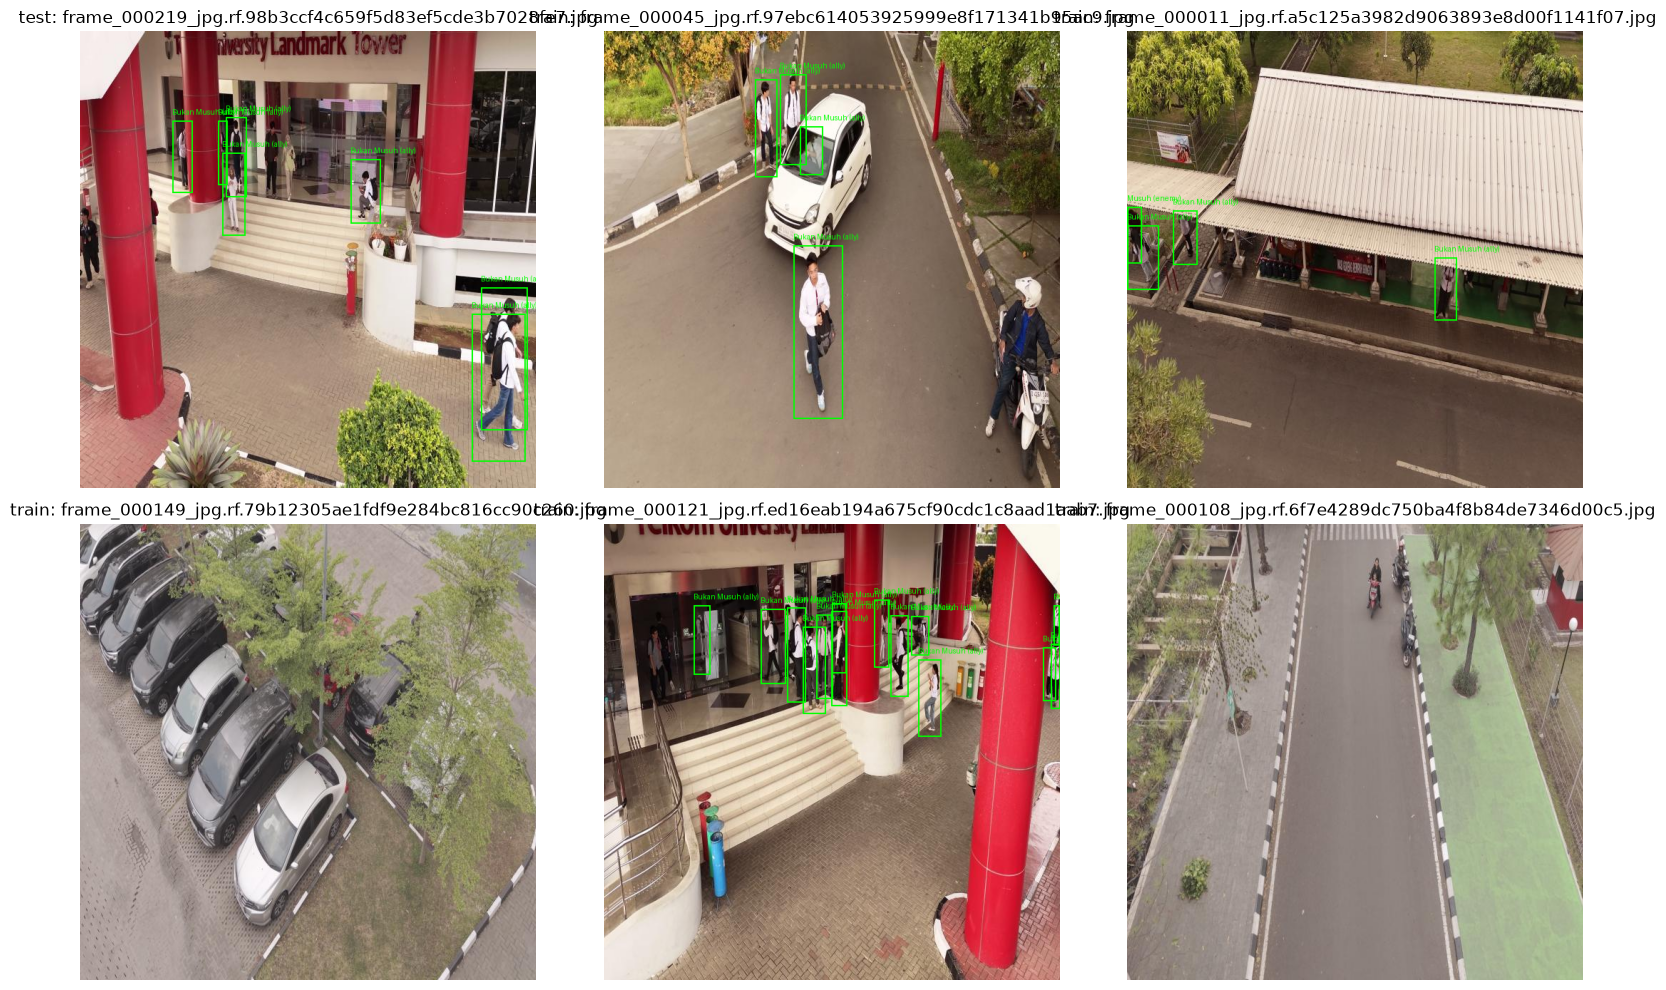

In [7]:
import math
import random
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

def preview_with_boxes(image_path, images_dir):
    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)
    width, height = image.size
    labels_path = label_path_for(image_path, images_dir)
    if labels_path.exists():
        for line in labels_path.read_text(encoding="utf-8").splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue
            class_id = int(float(parts[0]))
            x_center, y_center, box_width, box_height = map(float, parts[1:])
            x1 = int((x_center - box_width / 2) * width)
            y1 = int((y_center - box_height / 2) * height)
            x2 = int((x_center + box_width / 2) * width)
            y2 = int((y_center + box_height / 2) * height)
            draw.rectangle((x1, y1, x2, y2), outline="lime", width=max(2, width // 300))
            label = class_names[class_id] if 0 <= class_id < len(class_names) else f"id={class_id}"
            draw.text((x1, max(0, y1 - 18)), label, fill="lime")
    return image

preview_candidates = [(name, path) for name, paths in SAMPLE_IMAGES.items() for path in paths]
random.seed(42)
preview_candidates = random.sample(preview_candidates, min(6, len(preview_candidates)))
if not preview_candidates:
    raise ValueError("Tidak ada gambar yang ditemukan.")

columns = 3
rows = math.ceil(len(preview_candidates) / columns)
fig, axes = plt.subplots(rows, columns, figsize=(16, 5 * rows))
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]
for axis, (split_name, image_path) in zip(axes, preview_candidates):
    axis.imshow(preview_with_boxes(image_path, SPLIT_PATHS[split_name]))
    axis.set_title(f"{split_name}: {image_path.name}")
    axis.axis("off")
for axis in axes[len(preview_candidates):]:
    axis.axis("off")
plt.tight_layout()
plt.show()


## 7. Tulis YAML lokal dengan path absolut

Konfigurasi hasil ini menunjuk langsung ke split yang telah ditemukan pada audit, agar training tetap bekerja meski path relatif Roboflow berbeda.


In [8]:
local_meta = {
    "path": str(DATASET_DIR.resolve()),
    "train": str(SPLIT_PATHS["train"].resolve()),
    "val": str(SPLIT_PATHS["val"].resolve()),
    "nc": len(class_names),
    "names": class_names,
}
if "test" in SPLIT_PATHS:
    local_meta["test"] = str(SPLIT_PATHS["test"].resolve())

with LOCAL_DATA_YAML.open("w", encoding="utf-8") as file:
    yaml.safe_dump(local_meta, file, sort_keys=False, allow_unicode=True)

print(LOCAL_DATA_YAML.read_text(encoding="utf-8"))


path: F:\Telkom  x Machung\uav_enemy_detection_pt1\datasets\enemy-detection-1-fps-v1
train: F:\Telkom  x Machung\uav_enemy_detection_pt1\datasets\enemy-detection-1-fps-v1\train\images
val: F:\Telkom  x Machung\uav_enemy_detection_pt1\datasets\enemy-detection-1-fps-v1\valid\images
nc: 2
names:
- Bukan Musuh (ally)
- Musuh (enemy)
test: F:\Telkom  x Machung\uav_enemy_detection_pt1\datasets\enemy-detection-1-fps-v1\test\images



## 8. Pilih varian dan setelan training

MODEL_SIZE pada cell pertama adalah switcher n/s/m/l/x. batch=-1 meminta Ultralytics memperkirakan batch berdasarkan VRAM saat ini. Mulai dari n atau s; model besar dapat jauh lebih lambat dan otomatis memakai batch lebih kecil. Dataset sumber sudah berukuran 640x640, sehingga 640 menjadi baseline yang sesuai.


In [9]:
from ultralytics import YOLO

TRAIN_CONFIG = {
    "data": str(LOCAL_DATA_YAML),
    "epochs": 100,
    "imgsz": 640,
    "batch": -1,
    "device": DEVICE,
    "workers": 4,
    "patience": 25,
    "optimizer": "auto",
    "amp": USE_AMP,
    "cache": False,
    "seed": 42,
    "project": str(PROJECT_ROOT / "runs" / "train"),
    "name": f"enemy-yolo26{MODEL_SIZE}",
    "plots": True,
    "save": True,
    "save_period": 10,
    "verbose": True,
}
print(f"Model: {MODEL_WEIGHTS}")
print(f"Auto batch: {TRAIN_CONFIG['batch']}")
print(f"Device: {TRAIN_CONFIG['device']}")
print(f"Config: {TRAIN_CONFIG}")


Model: yolo26n.pt
Auto batch: -1
Device: 0
Config: {'data': 'F:\\Telkom  x Machung\\uav_enemy_detection_pt1\\datasets\\enemy-detection-1-fps-v1\\data_yolo26_local.yaml', 'epochs': 100, 'imgsz': 640, 'batch': -1, 'device': 0, 'workers': 4, 'patience': 25, 'optimizer': 'auto', 'amp': True, 'cache': False, 'seed': 42, 'project': 'F:\\Telkom  x Machung\\uav_enemy_detection_pt1\\runs\\train', 'name': 'enemy-yolo26n', 'plots': True, 'save': True, 'save_period': 10, 'verbose': True}


## 9. Mulai training

Cell ini menjalankan fine-tuning dari bobot pretrained YOLO26. Checkpoint dan grafik disimpan di folder runs/train.


In [ ]:
model = YOLO(MODEL_WEIGHTS)
train_results = model.train(**TRAIN_CONFIG)
RUN_DIR = Path(model.trainer.save_dir).resolve()
BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
LAST_WEIGHTS = RUN_DIR / "weights" / "last.pt"

print(f"Run: {RUN_DIR}")
print(f"Best checkpoint: {BEST_WEIGHTS}")
print(f"Last checkpoint: {LAST_WEIGHTS}")


### Lanjutkan training yang terputus

Jalankan cell berikut setelah menentukan checkpoint last.pt dari run yang ingin dilanjutkan.


In [ ]:
# RESUME_CHECKPOINT = LAST_WEIGHTS
# resume_model = YOLO(str(RESUME_CHECKPOINT))
# resume_results = resume_model.train(resume=True)


## 10. Evaluasi checkpoint terbaik

Jika dataset punya split test, evaluasi final menggunakan test. Jika tidak, notebook memakai val. Jangan gunakan test berulang kali untuk memilih setelan model.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

EVAL_SPLIT = "test" if "test" in SPLIT_PATHS else "val"
best_model = YOLO(str(BEST_WEIGHTS))
metrics = best_model.val(
    data=str(LOCAL_DATA_YAML),
    split=EVAL_SPLIT,
    device=DEVICE,
    plots=True,
    project=str(RUN_DIR / "evaluation"),
    name=EVAL_SPLIT,
    exist_ok=True,
)
VALIDATION_DIR = (RUN_DIR / "evaluation" / EVAL_SPLIT).resolve()
print(f"Split evaluasi: {EVAL_SPLIT}")
print(f"Folder hasil evaluasi: {VALIDATION_DIR}")

summary_metrics = pd.DataFrame(
    {
        "Nilai": [metrics.box.mp, metrics.box.mr, metrics.box.map50, metrics.box.map],
    },
    index=["Precision", "Recall", "mAP50", "mAP50-95"],
)
print("Metrik keseluruhan:")
display(summary_metrics.round(4))

# class_result menerima indeks posisi pada array metrik, sedangkan ap_class_index menyimpan ID kelas sumber.
per_class_rows = []
metric_class_ids = [int(class_id) for class_id in getattr(metrics.box, "ap_class_index", [])]
for metric_index, class_id in enumerate(metric_class_ids):
    precision, recall, ap50, ap = metrics.box.class_result(metric_index)
    class_name = class_names[class_id] if 0 <= class_id < len(class_names) else f"Class {class_id}"
    per_class_rows.append({
        "class_id": class_id,
        "kelas": class_name,
        "precision": precision,
        "recall": recall,
        "mAP50": ap50,
        "mAP50-95": ap,
    })
reported_ids = set(metric_class_ids)
for class_id, class_name in enumerate(class_names):
    if class_id not in reported_ids:
        per_class_rows.append({
            "class_id": class_id,
            "kelas": class_name,
            "precision": np.nan,
            "recall": np.nan,
            "mAP50": np.nan,
            "mAP50-95": np.nan,
        })
per_class_metrics = pd.DataFrame(per_class_rows).sort_values("class_id").reset_index(drop=True)
print("Metrik per kelas:")
display(per_class_metrics.round(4))

# Ultralytics detection matrix memakai baris=prediksi dan kolom=label aktual; kelas Background menampung FP/FN.
confusion = getattr(metrics, "confusion_matrix", None)
if confusion is None or getattr(confusion, "matrix", None) is None:
    print("Confusion matrix tidak tersedia pada objek metrics versi ini.")
else:
    confusion_matrix_raw = np.asarray(confusion.matrix, dtype=float)
    matrix_labels = list(class_names) + ["Background"]
    if confusion_matrix_raw.shape[0] != len(matrix_labels):
        matrix_labels = [f"Kelas {index}" for index in range(confusion_matrix_raw.shape[0] - 1)] + ["Background"]
    row_labels = [f"Prediksi: {label}" for label in matrix_labels]
    column_labels = [f"Aktual: {label}" for label in matrix_labels]
    confusion_matrix_counts = pd.DataFrame(
        confusion_matrix_raw.astype(int), index=row_labels, columns=column_labels
    )
    print("Matriks confusion (jumlah objek; baris=prediksi, kolom=aktual):")
    display(confusion_matrix_counts)

    # Normalisasi per kolom aktual agar tiap kelas aktual menunjukkan proporsi prediksi/FN-nya.
    actual_totals = confusion_matrix_raw.sum(axis=0, keepdims=True)
    confusion_matrix_normalized = np.divide(
        confusion_matrix_raw,
        actual_totals,
        out=np.zeros_like(confusion_matrix_raw, dtype=float),
        where=actual_totals != 0,
    )
    normalized_frame = pd.DataFrame(
        confusion_matrix_normalized, index=row_labels, columns=column_labels
    )
    print("Matriks confusion ternormalisasi per kelas aktual (0-1):")
    display(normalized_frame.round(3))

    VALIDATION_DIR.mkdir(parents=True, exist_ok=True)
    for matrix, title, filename, value_format in (
        (confusion_matrix_raw, "Confusion matrix (jumlah objek)", "confusion_matrix_counts_heatmap.png", "{:.0f}"),
        (confusion_matrix_normalized, "Confusion matrix (ternormalisasi per aktual)", "confusion_matrix_normalized_heatmap.png", "{:.2f}"),
    ):
        fig, axis = plt.subplots(figsize=(8, 7))
        image = axis.imshow(matrix, cmap="Blues", interpolation="nearest")
        axis.set_title(title)
        axis.set_xlabel("Label aktual")
        axis.set_ylabel("Prediksi model")
        axis.set_xticks(range(len(column_labels)), column_labels, rotation=35, ha="right")
        axis.set_yticks(range(len(row_labels)), row_labels)
        midpoint = float(np.nanmax(matrix)) / 2 if matrix.size and np.nanmax(matrix) > 0 else 0
        for row in range(matrix.shape[0]):
            for column in range(matrix.shape[1]):
                value = matrix[row, column]
                text_color = "white" if value > midpoint else "black"
                axis.text(column, row, value_format.format(value), ha="center", va="center", color=text_color)
        fig.colorbar(image, ax=axis, label="Proporsi" if "normalized" in filename else "Jumlah")
        fig.tight_layout()
        fig.savefig(VALIDATION_DIR / filename, dpi=160, bbox_inches="tight")
        plt.show()
        plt.close(fig)
    print(f"Heatmap confusion matrix tersimpan di: {VALIDATION_DIR}")


## 11. Grafik training dan evaluasi

Cell ini menampilkan kurva utama Ultralytics dan contoh validasi yang dibuat saat training/evaluasi. File yang belum tersedia akan dilewati.


In [ ]:
from IPython.display import display
from PIL import Image as PILImage

important_plot_names = [
    "results.png",
    "BoxPR_curve.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "labels.jpg",
    "val_batch0_labels.jpg",
    "val_batch0_pred.jpg",
]
plot_paths = []
for folder in (RUN_DIR, VALIDATION_DIR):
    for filename in important_plot_names:
        candidate = folder / filename
        if candidate.is_file() and candidate not in plot_paths:
            plot_paths.append(candidate)

if not plot_paths:
    print("Belum ada grafik tersimpan. Jalankan training dan evaluasi dengan plots=True terlebih dahulu.")
else:
    print(f"Menampilkan {len(plot_paths)} file grafik/visualisasi:")
    for plot_path in plot_paths:
        print(plot_path)
        with PILImage.open(plot_path) as plot_image:
            display(plot_image.copy())


## 12. Contoh prediksi perwakilan

Cell ini memilih contoh berlabel dari split test (atau val bila test tidak tersedia), menampilkan hasil deteksi, dan mencetak kelas, confidence, serta koordinat bounding box.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

EXAMPLE_SPLIT = "test" if "test" in SPLIT_PATHS else "val"
example_images_dir = SPLIT_PATHS[EXAMPLE_SPLIT]
example_candidates = SAMPLE_IMAGES[EXAMPLE_SPLIT]
representative_by_class = {}
for image_path in example_candidates:
    example_label_path = label_path_for(image_path, example_images_dir)
    if not example_label_path.exists():
        continue
    present_class_ids = set()
    for line in example_label_path.read_text(encoding="utf-8").splitlines():
        parts = line.split()
        if len(parts) == 5:
            try:
                present_class_ids.add(int(float(parts[0])))
            except ValueError:
                continue
    for class_id in range(len(class_names)):
        if class_id in present_class_ids and class_id not in representative_by_class:
            representative_by_class[class_id] = image_path
    if len(representative_by_class) == len(class_names):
        break

example_paths = []
for class_id in range(len(class_names)):
    candidate = representative_by_class.get(class_id)
    if candidate is not None and candidate not in example_paths:
        example_paths.append(candidate)
if not example_paths:
    example_paths = example_candidates[:min(2, len(example_candidates))]
if not example_paths:
    raise ValueError(f"Tidak ada gambar pada split {EXAMPLE_SPLIT}.")

EXAMPLE_CONFIDENCE = 0.25
example_results = best_model.predict(
    source=[str(path) for path in example_paths],
    conf=EXAMPLE_CONFIDENCE,
    imgsz=TRAIN_CONFIG["imgsz"],
    device=DEVICE,
    verbose=False,
    save=True,
    project=str(PROJECT_ROOT / "runs" / "predict"),
    name=f"examples-yolo26{MODEL_SIZE}",
    exist_ok=True,
)

prediction_rows = []
for result in example_results:
    boxes = result.boxes
    if boxes is not None and len(boxes):
        coordinates = boxes.xyxy.detach().cpu().tolist()
        class_ids = boxes.cls.detach().cpu().int().tolist()
        confidences = boxes.conf.detach().cpu().tolist()
        for xyxy, class_id, confidence in zip(coordinates, class_ids, confidences):
            class_name = class_names[class_id] if 0 <= class_id < len(class_names) else f"Class {class_id}"
            prediction_rows.append({
                "gambar": Path(result.path).name,
                "class_id": class_id,
                "kelas_prediksi": class_name,
                "confidence": confidence,
                "x1": xyxy[0], "y1": xyxy[1], "x2": xyxy[2], "y2": xyxy[3],
            })
    else:
        print(f"Tidak ada objek terdeteksi pada {Path(result.path).name}.")

print("Tabel prediksi (koordinat piksel x1, y1, x2, y2):")
if prediction_rows:
    predictions_df = pd.DataFrame(prediction_rows).sort_values("confidence", ascending=False).reset_index(drop=True)
    display(predictions_df.round(3))
else:
    predictions_df = pd.DataFrame(columns=["gambar", "class_id", "kelas_prediksi", "confidence", "x1", "y1", "x2", "y2"])
    display(predictions_df)

for result in example_results:
    rendered = result.plot(pil=True, labels=True, boxes=True)
    figure, axis = plt.subplots(figsize=(12, 7))
    axis.imshow(rendered)
    axis.set_title(f"Prediksi: {Path(result.path).name}")
    axis.axis("off")
    figure.tight_layout()
    plt.show()
    plt.close(figure)
print(f"Gambar contoh tersimpan di: {PROJECT_ROOT / 'runs' / 'predict' / f'examples-yolo26{MODEL_SIZE}'}")


## 13. Prediksi seluruh split dan ekspor opsional

Jalankan cell ini bila ingin menyimpan prediksi untuk semua gambar pada split test/val.


In [ ]:
PREDICT_SPLIT = "test" if "test" in SPLIT_PATHS else "val"
full_prediction_results = best_model.predict(
    source=str(SPLIT_PATHS[PREDICT_SPLIT]),
    conf=0.25,
    imgsz=TRAIN_CONFIG["imgsz"],
    device=DEVICE,
    save=True,
    project=str(PROJECT_ROOT / "runs" / "predict"),
    name=f"all-{PREDICT_SPLIT}-yolo26{MODEL_SIZE}",
    exist_ok=True,
)
print(f"Prediksi seluruh split {PREDICT_SPLIT} tersimpan: {PROJECT_ROOT / 'runs' / 'predict' / f'all-{PREDICT_SPLIT}-yolo26{MODEL_SIZE}'}")

# Ekspor opsional:
# onnx_path = best_model.export(format="onnx", imgsz=TRAIN_CONFIG["imgsz"])
# print(onnx_path)


## Catatan interpretasi

- Cocokkan nama dan urutan kelas pada data.yaml dengan label Musuh dan Bukan Musuh.
- Bila label Bukan Musuh tidak punya bounding box, dataset tersebut merepresentasikan contoh negatif, bukan kelas kedua yang terdeteksi.
- Periksa ketimpangan jumlah box per kelas; mAP per kelas dan confusion matrix lebih informatif daripada satu angka agregat.
- batch=-1 menyesuaikan pemakaian VRAM yang terdeteksi. Bila memilih x atau menaikkan imgsz, mulai dengan auto-batch; jika terjadi out-of-memory, turunkan resolusi atau gunakan nilai batch integer yang lebih kecil.
